<a href="https://colab.research.google.com/github/hamagami/IS2026/blob/main/09_GAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GAN: 生成器と識別器の交互学習 / GAN: Alternating generator and discriminator updates



生成器 $G(z)$ と識別器 $D(x)$ を交互に更新します．識別器のlogitにBCEWithLogitsLossを適用し，生成器は非飽和損失 $-\log D(G(z))$ を使います．損失が単調減少する学習ではなく，見た目と多様性も観察します．

Alternate updates to generator $G(z)$ and discriminator $D(x)$. Apply BCEWithLogitsLoss to discriminator logits and use the non-saturating generator loss $-\log D(G(z))$. Losses need not decrease monotonically; inspect visual quality and diversity as well.


## 準備 / Setup


In [ ]:
import sys, subprocess, importlib.util
# Colabの既存PyTorchを優先し，不足パッケージだけ追加します． / Reuse Colab packages; install only missing dependencies.
for module, package in [('torch','torch'), ('sklearn','scikit-learn'), ('ipywidgets','ipywidgets')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])
import random, math, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
import ipywidgets as widgets
from IPython.display import display, clear_output
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(2)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'figure.dpi':110, 'font.size':11, 'axes.spines.top':False, 'axes.spines.right':False})
print('PyTorch:', torch.__version__, '| 実行機器 / Device:', device)


# 日本語フォントを設定します． / Configure a Japanese font for bilingual figures.
if importlib.util.find_spec('japanize_matplotlib') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'japanize-matplotlib'])
import japanize_matplotlib
plt.rcParams['axes.unicode_minus'] = False


PyTorch: 2.14.1+cu130 | 実行機器 / Device: cuda


## 設定 / Configuration


In [ ]:
BATCH_SIZE=128
LATENT_DIM=16
TRAIN_STEPS=1800
SNAPSHOT_EVERY=300
LEARNING_RATE=.0002


## データ / Data


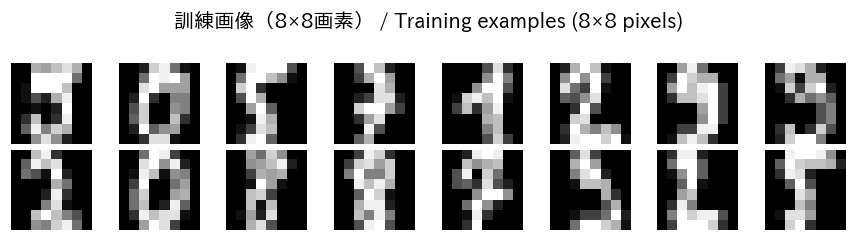

訓練数 / Train: 1437 | 評価数 / Held-out: 360


In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
raw = load_digits()
# sklearn同梱の8×8手書き数字．通信・認証は不要です． / Use the bundled sklearn 8×8 digits; no dataset download or authentication.
# 画像モデルの学習にクラスラベルは使いません．可視化だけに使います． / Class labels are used for visualization, not image-model training.
images = (raw.data / 16.0).astype('float32')
train_idx, test_idx = train_test_split(np.arange(len(images)), test_size=0.2,
                                    random_state=SEED, stratify=raw.target)
x_train = torch.tensor(images[train_idx])
x_test = torch.tensor(images[test_idx])
y_test = raw.target[test_idx]
loader = DataLoader(TensorDataset(x_train), batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
def image_grid(x, title='', nrow=8):
    x = torch.as_tensor(x).detach().cpu().reshape(-1,8,8).numpy()
    rows = math.ceil(len(x)/nrow)
    fig, ax = plt.subplots(rows,nrow,figsize=(nrow,rows*1.1),squeeze=False)
    for a in ax.ravel(): a.axis('off')
    for a,im in zip(ax.ravel(),x): a.imshow(im,cmap='gray',vmin=0,vmax=1)
    fig.suptitle(title); plt.tight_layout(); plt.show()
image_grid(x_train[:16], '訓練画像（8×8画素） / Training examples (8×8 pixels)')
print('訓練数 / Train:',len(x_train),'| 評価数 / Held-out:',len(x_test))


## モデル / Model


In [ ]:
class Generator(nn.Module):
    def __init__(self):
        super().__init__();self.net=nn.Sequential(nn.Linear(LATENT_DIM,128),nn.LeakyReLU(.2),nn.Linear(128,256),nn.LeakyReLU(.2),nn.Linear(256,64),nn.Tanh())
    def forward(self,z):return self.net(z)
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__();self.net=nn.Sequential(nn.Linear(64,128),nn.LeakyReLU(.2),nn.Linear(128,64),nn.LeakyReLU(.2),nn.Linear(64,1))
    def forward(self,x):return self.net(x).squeeze(1)
G,D=Generator().to(device),Discriminator().to(device)
optG=torch.optim.Adam(G.parameters(),lr=LEARNING_RATE,betas=(.5,.999))
optD=torch.optim.Adam(D.parameters(),lr=LEARNING_RATE,betas=(.5,.999))
fixed_z=torch.randn(24,LATENT_DIM,device=device)
# 元画像は[-1,1]へ．教師ラベルではなく，real/fakeの人工的な目標を使います． / Scale images to [-1,1]; use artificial real/fake targets instead of digit labels.
data=x_train.to(device)*2-1
snapshots=[];history=[]


## 学習 / Training


ステップ / Step 1: 識別器 / D=1.408, 生成器 / G=0.631
ステップ / Step 300: 識別器 / D=1.249, 生成器 / G=0.793
ステップ / Step 600: 識別器 / D=1.075, 生成器 / G=1.052
ステップ / Step 900: 識別器 / D=1.386, 生成器 / G=1.012
ステップ / Step 1200: 識別器 / D=1.186, 生成器 / G=1.013
ステップ / Step 1500: 識別器 / D=1.081, 生成器 / G=1.080
ステップ / Step 1800: 識別器 / D=1.099, 生成器 / G=1.137
経過時間 / Elapsed: 10.0s


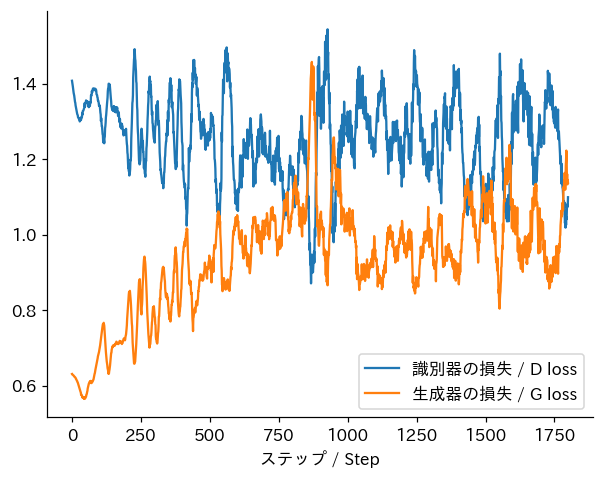

In [ ]:
start=time.time()
for step in range(TRAIN_STEPS):
    # Dの更新: Gには勾配を流さない / D update: do not backpropagate into G.
    for p in D.parameters():p.requires_grad_(True)
    real=data[torch.randint(len(data),(BATCH_SIZE,),device=device)]
    fake=G(torch.randn(BATCH_SIZE,LATENT_DIM,device=device))
    optD.zero_grad()
    lossD=F.binary_cross_entropy_with_logits(D(real),torch.full((BATCH_SIZE,),.9,device=device))
    lossD+=F.binary_cross_entropy_with_logits(D(fake.detach()),torch.zeros(BATCH_SIZE,device=device))
    lossD.backward();optD.step()
    # Gの更新: Dのパラメータは固定し，入力方向の勾配だけGへ伝える / G update: freeze D parameters while passing input gradients through D to G.
    for p in D.parameters():p.requires_grad_(False)
    optG.zero_grad();fake=G(torch.randn(BATCH_SIZE,LATENT_DIM,device=device))
    lossG=F.binary_cross_entropy_with_logits(D(fake),torch.ones(BATCH_SIZE,device=device))
    lossG.backward();optG.step()
    history.append((lossD.item(),lossG.item()))
    if step==0 or (step+1)%SNAPSHOT_EVERY==0:
        with torch.no_grad():snapshots.append((step+1,(G(fixed_z).cpu()+1)/2))
        print(f'ステップ / Step {step+1}: 識別器 / D={lossD.item():.3f}, 生成器 / G={lossG.item():.3f}')
print(f'経過時間 / Elapsed: {time.time()-start:.1f}s')
plt.plot(np.array(history));plt.legend(['識別器の損失 / D loss','生成器の損失 / G loss']);plt.xlabel('ステップ / Step');plt.show()


## インタラクティブ操作 / Interactive controls


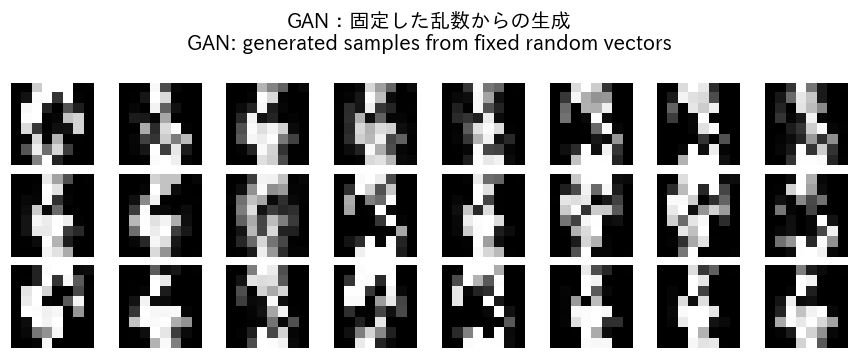

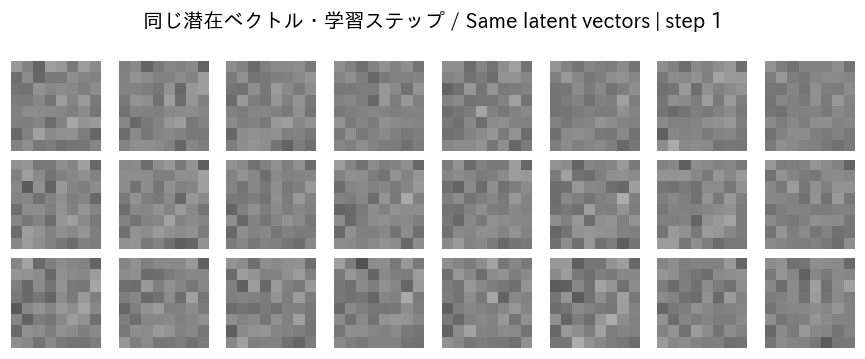

interactive(children=(IntSlider(value=6, continuous_update=False, description='記録時点 / Snapshot', layout=Layout…

<function __main__.show_snapshot(index=0)>

In [ ]:
image_grid(snapshots[-1][1],'GAN：固定した乱数からの生成\nGAN: generated samples from fixed random vectors')
def show_snapshot(index=0):
    step,ims=snapshots[index];image_grid(ims,f'同じ潜在ベクトル・学習ステップ / Same latent vectors | step {step}')
show_snapshot(0)
widgets.interact(show_snapshot,index=widgets.IntSlider(min=0,max=len(snapshots)-1,value=len(snapshots)-1,description='記録時点 / Snapshot', style={'description_width':'initial'}, layout=widgets.Layout(width='auto',min_width='260px'),continuous_update=False))


## 評価と可視化 / Evaluation and visualization


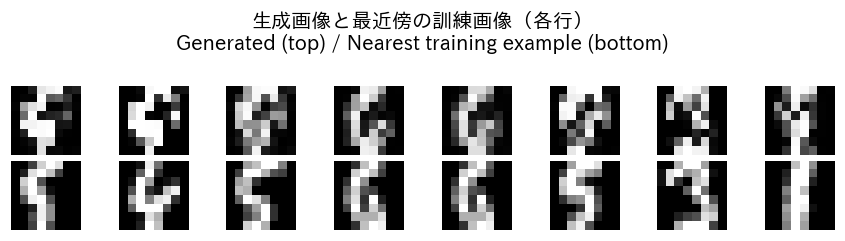

In [ ]:
# 最も近い訓練画像との比較は，類似性を点検する簡易チェックです．一般化の証明ではありません． / Nearest-training-image comparison checks similarity; it does not prove generalization.
G.eval()
with torch.no_grad():samples=(G(torch.randn(8,LATENT_DIM,device=device)).cpu()+1)/2
nearest=torch.cdist(samples,x_train).argmin(1)
image_grid(torch.cat([samples,x_train[nearest]]),'生成画像と最近傍の訓練画像（各行）\nGenerated (top) / Nearest training example (bottom)',nrow=8)


## 観察すること / What to observe
- 固定したzに対する画像が学習中にどう変わるか．
  How do images from fixed latent vectors change during training?
- 多くのzが似た数字になるmode collapseがないか．
  Check for mode collapse: do many latent vectors produce similar digits?
- TRAIN_STEPSや学習率を変えて比較する．小型GANの学習は不安定で，毎回きれいな10種類が得られるとは限りません．
  Compare different TRAIN_STEPS and learning rates. Small GANs can be unstable; ten clear digit classes are not guaranteed in every run.


## 参考 / References
- [PyTorch DCGAN tutorial](https://docs.pytorch.org/tutorials/beginner/dcgan_faces_tutorial.html)
- [Generative Adversarial Nets](https://arxiv.org/abs/1406.2661)
